# **Trabalho Prático 1** (TP1)
`49774`: Francisco Valentim | `51811`: Bruno Pereira

**Instituto Superior de Engenharia de Lisboa** (ISEL)<br>
**Licenciatura em Engenharia Informática e Multimédia** (LEIM)<br>
**Processamento de Sinais Multimédia** (PSM)

---

O processador tem três blocos. $(1)$ O primeiro é um equalizador de 3 bandas com filtros FIR (*Parte A*). $(2)$ O segundo é um reverberador de Schroeder com filtros IIR (*Parte B*). $(3)$ O terceiro mistura o som direto com o som reverberado.

O equalizador e o reverberador estão associados em série. A saída do equalizador, $x_{eq}[n]$, está à entrada do reverberador, que produz $y_{reverb}[n]$. O sinal resultante é $y[n] = (1 - \alpha)\, x_{eq}[n] + \alpha\, y_{reverb}[n].$

## $0.$ Bibliotecas, parâmetros e funções auxiliares

In [ ]:
import os
from math import gcd

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, lfilter, freqz, unit_impulse
from scipy.io import wavfile
from IPython.display import Audio, display

In [2]:
Fs = 44100                          # frequência de amostragem (Hz)

L   = 101                           # comprimento dos filtros FIR (nº de coeficientes)
FC1 = 300                           # fronteira graves / médios (Hz)
FC2 = 3000                          # fronteira médios / agudos (Hz)
BASS_BOOST   = (2.0, 1.0, 0.5)      # (g1, g2, g3)
TREBLE_BOOST = (0.5, 1.0, 2.0)

T_COMB = (29.7, 37.1, 41.1, 43.7)   # atrasos dos filtros Comb (ms)
G_COMB = (0.75, 0.75, 0.75, 0.75)   # ganhos de realimentação, em [0.70, 0.80]
T_AP   = (5.0, 1.7)                 # atrasos dos filtros All-Pass (ms)
A_AP   = 0.7                        # coeficiente dos filtros All-Pass

AUDIO_IN  = os.path.join('audio', 'in')    # sinais originais
AUDIO_OUT = os.path.join('audio', 'out')   # sinais processados

In [ ]:
def normalize(x, peak=0.99):
    """Normaliza um sinal pelo pico.
    Args:
        x: Sinal.
        peak: Pico pretendido.
    Returns:
        Sinal com max|x| = peak, ou x se for nulo.
    """
    m = np.max(np.abs(x))
    return x if m == 0 else peak * x / m

def db(x, floor=1e-12):
    """Converte amplitude em dB.
    Args:
        x: Amplitude (real ou complexa).
        floor: Valor somado a |x| para evitar log10(0).
    Returns:
        20·log10(|x| + floor).
    """
    return 20 * np.log10(np.abs(x) + floor)

def freq_response(b, a=1.0, worN=16384):
    """Resposta em frequência de um SLIT definido por H(z) = B(z)/A(z).
    Args:
        b: Coeficientes do numerador.
        a: Coeficientes do denominador.
        worN: Nº de pontos em [0, Fs/2], ou vetor de frequências (Hz).
    Returns:
        (f, H): frequências (Hz) e H(e^jω).
    """
    return freqz(b, a, worN=worN, fs=Fs)

def read_wav(path):
    """Lê um ficheiro .wav para um sinal mono em [-1, 1].
    Args:
        path: Caminho do ficheiro.
    Returns:
        Sinal em vírgula flutuante.
    Raises:
        ValueError: Se a frequência de amostragem for diferente de Fs.
    """
    fs, x = wavfile.read(path)
    if fs != Fs:
        raise ValueError(f'{path}: Fs = {fs} Hz (esperado {Fs} Hz).')
    if np.issubdtype(x.dtype, np.integer):
        x = x / float(np.iinfo(x.dtype).max + 1)
    if x.ndim == 2:
        x = x.mean(axis=1)
    return x.astype(float)

def write_wav(path, x):
    """Grava um sinal em [-1, 1] como .wav PCM de 16 bits.
    Args:
        path: Caminho do ficheiro.
        x: Sinal.
    """
    wavfile.write(path, Fs, (np.clip(x, -1, 1) * (2**15 - 1)).astype(np.int16))

In [ ]:
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['axes.grid'] = True

def format_freq_axis(ax, title, xlim=(20, Fs / 2), ylim=(-90, 5), marks=(FC1, FC2)):
    """Formata um eixo de resposta em amplitude (escala logarítmica).
    Args:
        ax: Eixo do matplotlib.
        title: Título.
        xlim: Limites das frequências (Hz).
        ylim: Limites da amplitude (dB).
        marks: Frequências assinaladas a tracejado (Hz).
    """
    ax.set_xscale('log'); ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    for fc in marks:
        ax.axvline(fc, color='gray', ls='--', lw=1)
    ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('Amplitude (dB)')
    ax.set_title(title); ax.grid(True, which='both', alpha=0.4); ax.legend(fontsize=9)

## $1.$ **Parte A:** equalizador FIR

### $1.1.$ Filtros

Um filtro FIR é um sistema não recursivo. A saída é uma soma pesada de valores presentes e passados da entrada:

$$y[n] = \sum_{k=0}^{M} b_k\, x[n-k].$$

Os coeficientes $b_k$ coincidem com a resposta impulsional $h[n]$. Cada filtro tem $L = 101$ coeficientes, o que corresponde à ordem $M = L - 1 = 100$.

A função `firwin` obtém os coeficientes pela técnica de janelamento, com a janela de Hamming. No passa-banda e no passa-alto, `pass_zero=False` exclui 0 Hz da banda de passagem. Por omissão (`scale=True`), cada filtro tem ganho 1 na sua banda de passagem.

In [5]:
h_low  = firwin(L, FC1,        window='hamming', fs=Fs)
h_mid  = firwin(L, [FC1, FC2], window='hamming', fs=Fs, pass_zero=False)
h_high = firwin(L, FC2,        window='hamming', fs=Fs, pass_zero=False)

FILTERS = [(h_low,  f'Graves — passa-baixo {FC1} Hz'),
           (h_mid,  f'Médios — passa-banda {FC1}–{FC2} Hz'),
           (h_high, f'Agudos — passa-alto {FC2} Hz')]

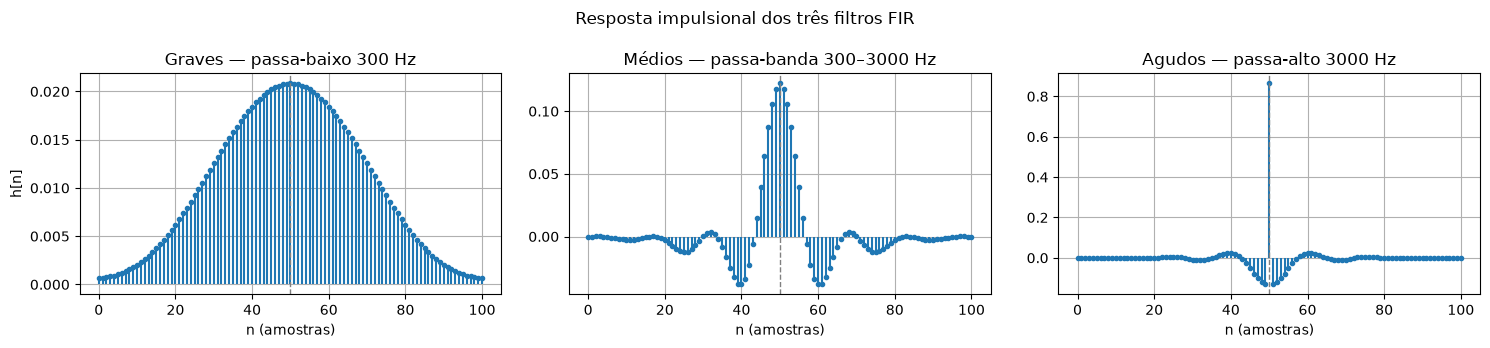

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (h, name) in zip(axs, FILTERS):
    ax.stem(np.arange(L), h, basefmt=' ')[0].set_markersize(3)
    ax.axvline((L - 1) / 2, color='gray', ls='--', lw=1)
    ax.set_title(name); ax.set_xlabel('n (amostras)')
axs[0].set_ylabel('h[n]')
fig.suptitle('Resposta impulsional dos três filtros FIR')
plt.tight_layout(); plt.show()

**Interpretação:** Cada resposta impulsional é simétrica em torno de $n = (L-1)/2 = 50$. Esta simetria dá aos filtros fase linear, pelo que todas as frequências sofrem o mesmo atraso de 50 amostras (1,13 ms). As saídas dos três filtros ficam alinhadas no tempo e podem ser somadas diretamente.

### $1.2.$ Resposta em Amplitude

A resposta em frequência $H(e^{j\omega})$ é a Transformada de Fourier de $h[n]$. A resposta em amplitude é $|H(e^{j\omega})|$, representada em dB. $$|H|_{dB} = 20\log_{10}|H|$$

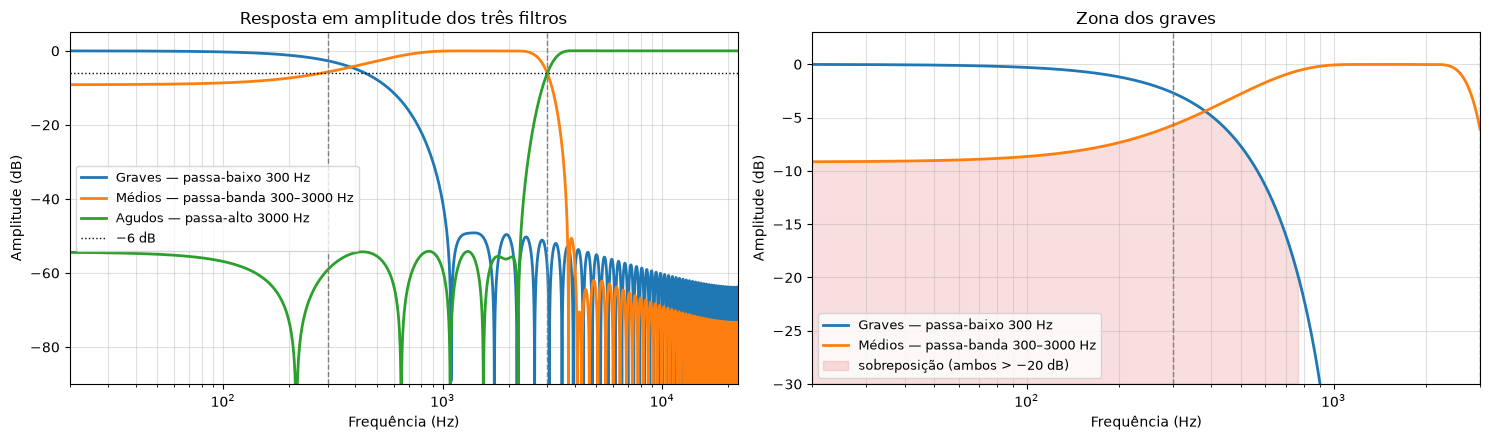

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for h, name in FILTERS:
    f, H = freq_response(h)
    ax1.plot(f, db(H), lw=2, label=name)
ax1.axhline(-6, color='k', ls=':', lw=1, label='−6 dB')
format_freq_axis(ax1, 'Resposta em amplitude dos três filtros')

f, Hl = freq_response(h_low)
_, Hm = freq_response(h_mid)
overlap = np.minimum(db(Hl), db(Hm))
ax2.plot(f, db(Hl), lw=2, label=FILTERS[0][1])
ax2.plot(f, db(Hm), lw=2, label=FILTERS[1][1])
ax2.fill_between(f, -30, overlap, where=overlap > -20, color='C3', alpha=0.15,
                 label='sobreposição (ambos > −20 dB)')
format_freq_axis(ax2, 'Zona dos graves', xlim=(20, 3000), ylim=(-30, 3))
plt.tight_layout(); plt.show()

**Interpretação:** Na banda de passagem, cada filtro tem ganho próximo de 0 dB. Na banda de corte, a atenuação fica entre 50 e 60 dB. O passa-banda e o passa-alto cruzam-se a −6 dB em 3000 Hz.

Nos graves, o passa-baixo e o passa-banda sobrepõem-se (zona sombreada no gráfico da direita). Com 101 coeficientes, a banda de transição tem cerca de 1,4 kHz, mais do que toda a banda dos graves (0 a 300 Hz). Em 0 Hz, o passa-banda atenua apenas 9 dB. Em 600 Hz, o passa-baixo atenua apenas 11 dB.

### $1.3.$ Equalizador

Os três filtros estão associados em paralelo. A resposta impulsional do conjunto é a soma das respostas impulsionais, pesadas pelos ganhos:

$$h_{eq}[n] = g_1\, h_{graves}[n] + g_2\, h_{médios}[n] + g_3\, h_{agudos}[n].$$

O equalizador é um único filtro FIR com 101 coeficientes. Pela linearidade da convolução, filtrar com $h_{eq}$ produz a soma pesada das saídas das três bandas.

In [ ]:
def equalizer_ir(g1, g2, g3):
    """Resposta impulsional do equalizador.
    Args:
        g1, g2, g3: Ganhos lineares dos graves, médios e agudos.
    Returns:
        h_eq = g1·h_low + g2·h_mid + g3·h_high.
    Raises:
        ValueError: Se algum ganho for negativo.
    """
    if min(g1, g2, g3) < 0:
        raise ValueError('Os ganhos têm de ser >= 0.')
    return g1 * h_low + g2 * h_mid + g3 * h_high


def equalizer(x, g1, g2, g3):
    """Aplica o equalizador de 3 bandas.
    Args:
        x: Sinal de entrada.
        g1, g2, g3: Ganhos lineares dos graves, médios e agudos.
    Returns:
        x_eq, com o comprimento de x.
    """
    return lfilter(equalizer_ir(g1, g2, g3), 1.0, x)

CONFIGS = [(BASS_BOOST,   'Bass Boost (2; 1; 0,5)'),
           (TREBLE_BOOST, 'Treble Boost (0,5; 1; 2)')]

### $1.4.$ Resposta em frequência combinada

Um ganho linear $g$ corresponde a $20\log_{10} g$ dB. Os ganhos 2 e 0,5 correspondem a +6 dB e −6 dB.

| Configuração | $(g_1, g_2, g_3)$ | Ganho ideal (graves / médios / agudos) |
| :--- | :--- | :--- |
| Bass Boost | (2; 1; 0,5) | +6 / 0 / −6 dB |
| Treble Boost | (0,5; 1; 2) | −6 / 0 / +6 dB |

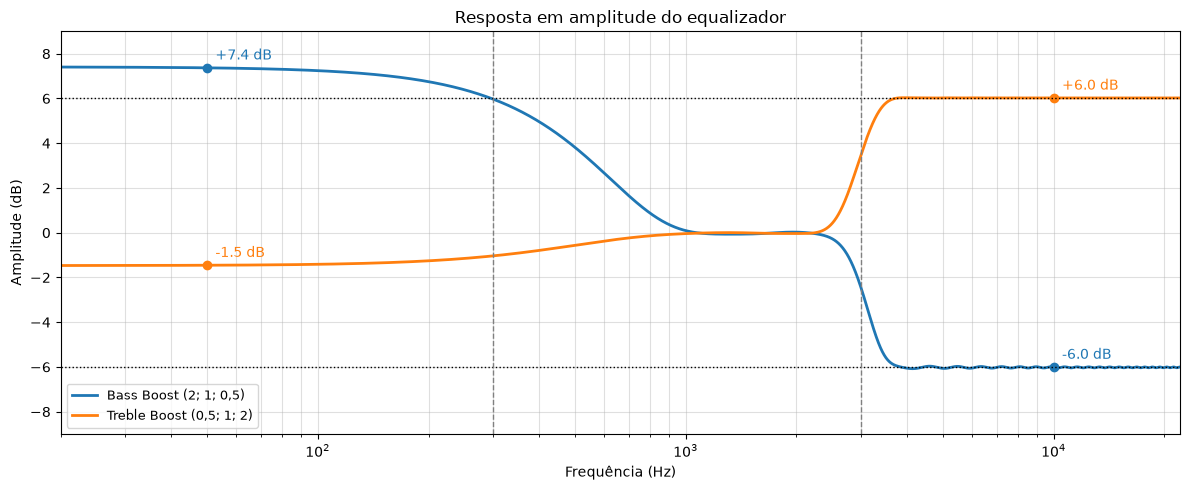

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
for k, (gains, name) in enumerate(CONFIGS):
    f, H = freq_response(equalizer_ir(*gains))
    ax.plot(f, db(H), lw=2, color=f'C{k}', label=name)
    for f0 in (50, 10000):
        v = db(H[np.argmin(np.abs(f - f0))])
        ax.plot(f0, v, 'o', color=f'C{k}')
        ax.annotate(f'{v:+.1f} dB', (f0, v), textcoords='offset points', xytext=(6, 6), color=f'C{k}')
for level in (6.02, -6.02):
    ax.axhline(level, color='k', ls=':', lw=1)
format_freq_axis(ax, 'Resposta em amplitude do equalizador', ylim=(-9, 9))
plt.tight_layout(); plt.show()

#### Interpretação

Nos médios, o ganho é 0 dB nas duas configurações. Nos agudos, é ±6 dB, como previsto.

Nos graves, o resultado afasta-se do ideal. O passa-banda deixa passar cerca de 35 % da amplitude a baixa frequência (−9 dB), e o ganho real dos graves passa a ser $g_1 + 0{,}35\, g_2$. O Bass Boost dá +7,4 dB em vez de +6 dB, e o Treble Boost dá −1,4 dB em vez de −6 dB.

### 1.5 Validação com sinusóides

Num SLIT, uma sinusóide de frequência $\omega$ produz à saída uma sinusóide com a mesma frequência, com a amplitude multiplicada por $|H(\omega)|$. Aplicam-se ao equalizador tons de amplitude 1, e a amplitude de saída é comparada com $|H|$ calculado pelo `freqz`. As primeiras $L$ amostras da saída correspondem ao regime transitório e são ignoradas.

In [10]:
TONE_FREQS = [100, 300, 1000, 3000, 8000]
t_tone = np.arange(Fs) / Fs     # 1 s

def tone_gain(f0, gains):
    """Amplitude de saída do equalizador para um tom de amplitude 1.

    Args:
        f0: Frequência do tom (Hz).
        gains: Ganhos (g1, g2, g3).

    Returns:
        Pico da saída em regime permanente.
    """
    y = equalizer(np.sin(2 * np.pi * f0 * t_tone), *gains)
    return np.max(np.abs(y[L:]))

measured = {name: [tone_gain(f0, gains) for f0 in TONE_FREQS] for gains, name in CONFIGS}

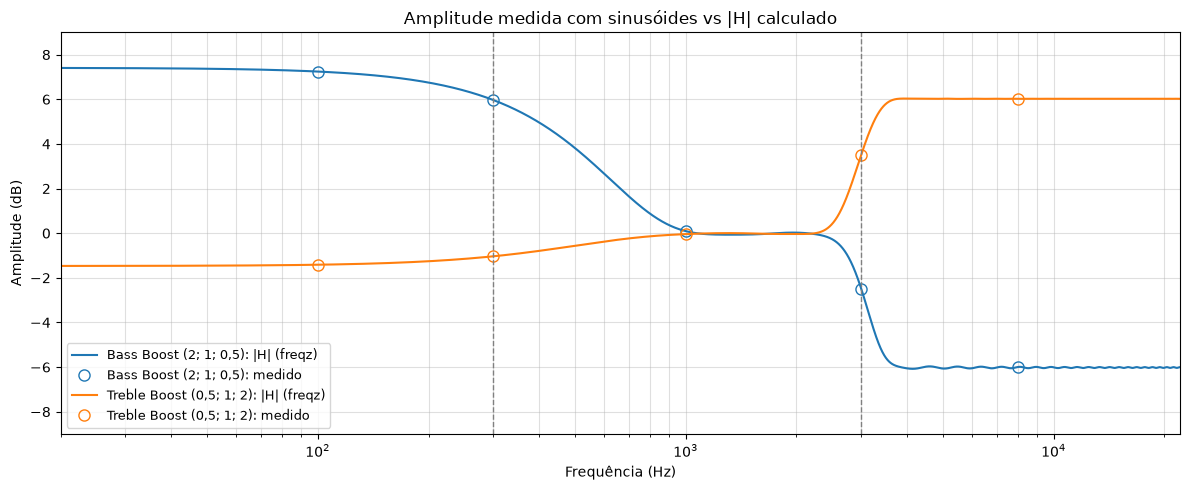

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
for k, (gains, name) in enumerate(CONFIGS):
    f, H = freq_response(equalizer_ir(*gains))
    ax.plot(f, db(H), lw=1.5, color=f'C{k}', label=f'{name}: |H| (freqz)')
    ax.plot(TONE_FREQS, db(np.array(measured[name])), 'o', ms=8, mfc='none', color=f'C{k}',
            label=f'{name}: medido')
format_freq_axis(ax, 'Amplitude medida com sinusóides vs |H| calculado', ylim=(-9, 9))
plt.tight_layout(); plt.show()

#### Interpretação

Os valores medidos coincidem com as curvas de $|H|$. Isto confirma, no domínio do tempo, a resposta em frequência calculada pelo `freqz`.

## 2. Parte B: reverberador de Schroeder

O reverberador associa dois blocos em série: um banco de 4 filtros Comb em paralelo, seguido de uma cascata de 2 filtros All-Pass. Os dois tipos de filtro são sistemas recursivos (IIR), porque a saída depende de valores passados da própria saída.

### 2.1 Atrasos

Um atraso de $T$ ms corresponde a $N = \mathrm{round}(T \cdot F_s / 1000)$ amostras. O enunciado pede tempos primos entre si, mas o arredondamento pode quebrar esta condição. Por exemplo, 29,7 ms e 37,1 ms dão 1310 e 1636 amostras, e $\mathrm{mdc}(1310, 1636) = 2$.

A função `coprime_delays` incrementa cada atraso até ficar primo com todos os anteriores. A condição aplica-se aos seis atrasos, dos Comb e dos All-Pass.

In [12]:
def coprime_delays(times_ms):
    """Converte tempos em atrasos (amostras) primos entre si.

    Args:
        times_ms: Tempos (ms).

    Returns:
        Lista de atrasos; cada um é o menor inteiro >= round(T·Fs) primo com os anteriores.
    """
    delays = []
    for t in times_ms:
        N = round(t * Fs / 1000)
        while any(gcd(N, m) > 1 for m in delays):
            N += 1
        delays.append(N)
    return delays


N_ALL  = coprime_delays(T_COMB + T_AP)
N_COMB = N_ALL[:len(T_COMB)]
N_AP   = N_ALL[len(T_COMB):]

In [13]:
print(f'{"Filtro":<11}{"T (ms)":>8}{"round":>8}{"N usado":>9}{"T efetivo (ms)":>16}')
for name, t, N in zip([f'Comb {k + 1}' for k in range(4)] + ['All-Pass 1', 'All-Pass 2'],
                      T_COMB + T_AP, N_COMB + N_AP):
    print(f'{name:<11}{t:>8.1f}{round(t * Fs / 1000):>8}{N:>9}{1000 * N / Fs:>16.2f}')

Filtro       T (ms)   round  N usado  T efetivo (ms)
Comb 1         29.7    1310     1310           29.71
Comb 2         37.1    1636     1637           37.12
Comb 3         41.1    1813     1813           41.11
Comb 4         43.7    1927     1927           43.70
All-Pass 1      5.0     220      221            5.01
All-Pass 2      1.7      75       79            1.79


### 2.2 Filtro Comb

A equação às diferenças é

$$y_c[n] = x[n] + g\, y_c[n - N].$$

Aplicando a TZ e a propriedade do deslocamento no tempo, obtém-se $Y(z) = X(z) + g\, z^{-N}\, Y(z)$. A função de transferência é

$$H_c(z) = \frac{1}{1 - g\, z^{-N}}.$$

Os pólos são as raízes de $z^N = g$. São $N$ pólos com raio $|z| = g^{1/N}$. Como $g < 1$, ficam todos no interior do círculo de raio unitário, e o sistema causal é estável.

Desenvolvendo $H_c(z)$ como série geométrica de razão $g\,z^{-N}$, a resposta impulsional é

$$h_c[n] = \sum_{m=0}^{\infty} g^m\, \delta[n - mN].$$

Trata-se de um trem de impulsos espaçados de $N$ amostras, em que a amplitude é multiplicada por $g$ a cada $N$ amostras.

Com $z = e^{j\omega}$, a resposta em amplitude é

$$|H_c(\omega)| = \frac{1}{|1 - g\, e^{-j\omega N}|}.$$

Os máximos valem $1/(1-g)$ e ocorrem em $f = k\, F_s / N$. Entre eles, os mínimos valem $1/(1+g)$. É esta forma em pente que dá o nome ao filtro. Os picos periódicos colorem o som, o que se ouve como uma ressonância metálica.

No banco em paralelo, a função de transferência é a soma $H_{comb}(z) = \sum_{k=1}^{4} H_{c,k}(z)$. Como os atrasos são primos entre si, os picos de dois filtros só coincidem em $f = 0$ e nos múltiplos de $F_s$. Os ecos de dois filtros só coincidem ao fim de $N_i \cdot N_j$ amostras, o que dá mais de 45 s.

In [14]:
def comb_coefs(N, g):
    """Coeficientes de H(z) = 1 / (1 - g·z^-N).

    Args:
        N: Atraso (amostras).
        g: Ganho de realimentação.

    Returns:
        (b, a): numerador e denominador.
    """
    a = np.zeros(N + 1)
    a[0], a[N] = 1.0, -g
    return np.array([1.0]), a


h_comb1 = lfilter(*comb_coefs(N_COMB[0], G_COMB[0]), unit_impulse(Fs // 2))

f_comb = np.linspace(0, 250, 5000)
H_combs = [freq_response(*comb_coefs(N, g), worN=f_comb)[1] for N, g in zip(N_COMB, G_COMB)]
H_bank = np.sum(H_combs, axis=0)

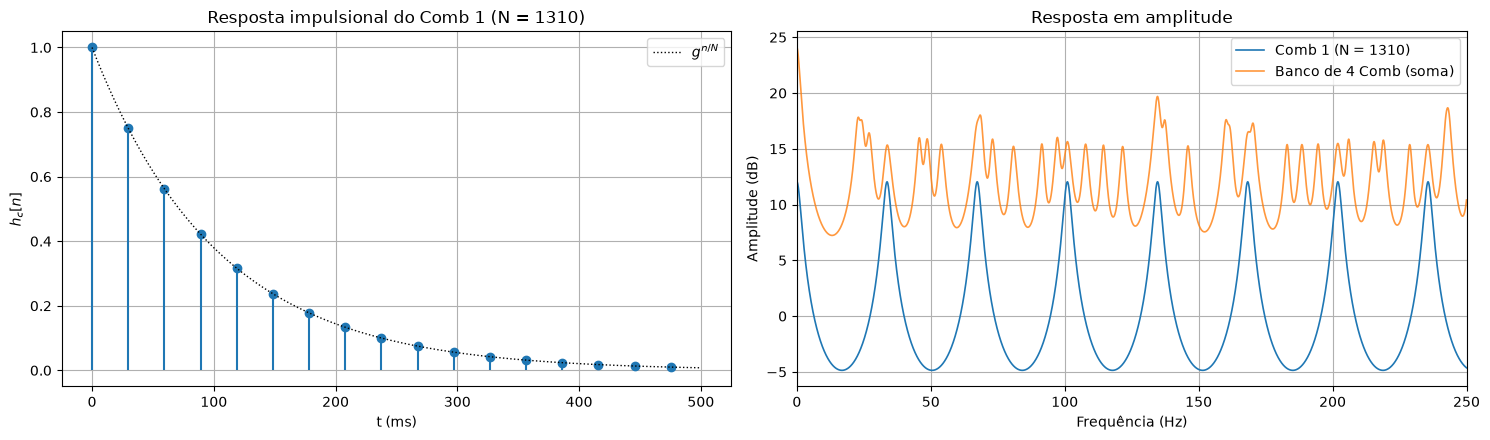

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
n = np.arange(len(h_comb1))
nz = np.flatnonzero(h_comb1)
ax1.stem(1000 * nz / Fs, h_comb1[nz], basefmt=' ')
ax1.plot(1000 * n / Fs, G_COMB[0] ** (n / N_COMB[0]), 'k:', lw=1, label=r'$g^{n/N}$')
ax1.set_xlabel('t (ms)'); ax1.set_ylabel(r'$h_c[n]$'); ax1.legend()
ax1.set_title(f'Resposta impulsional do Comb 1 (N = {N_COMB[0]})')

ax2.plot(f_comb, db(H_combs[0]), lw=1.2, label=f'Comb 1 (N = {N_COMB[0]})')
ax2.plot(f_comb, db(H_bank), lw=1.2, alpha=0.8, label='Banco de 4 Comb (soma)')
ax2.set_xlabel('Frequência (Hz)'); ax2.set_ylabel('Amplitude (dB)'); ax2.set_xlim(0, 250)
ax2.set_title('Resposta em amplitude'); ax2.legend()
plt.tight_layout(); plt.show()

#### Interpretação

No gráfico da esquerda, $h_c[n]$ tem um impulso a cada 1310 amostras (29,7 ms), e a amplitude segue a envolvente $g^{n/N}$.

No gráfico da direita, os picos de $|H|$ do Comb 1 valem $1/(1-0{,}75) = 4$ (+12 dB) e estão espaçados de $F_s/N \approx 33{,}7$ Hz. Os mínimos valem $1/(1+0{,}75) \approx 0{,}57$ (−4,9 dB). No banco, os picos dos quatro filtros ficam em posições diferentes e a resposta deixa de ser periódica. Em $f = 0$ os quatro picos somam-se, e o ganho chega a $\sum 1/(1-g_k) = 16$ (+24 dB). Um ganho tão alto obriga a normalizar a saída.

### 2.3 Filtro All-Pass

A equação às diferenças é

$$y_{ap}[n] = -a\, x[n] + x[n - N] + a\, y_{ap}[n - N].$$

A função de transferência é

$$H_{ap}(z) = \frac{-a + z^{-N}}{1 - a\, z^{-N}}.$$

Os pólos têm raio $|z| = a^{1/N} < 1$, pelo que o sistema causal é estável. Os zeros são as raízes de $z^N = 1/a$ e têm raio $|z| = a^{-1/N} > 1$. Cada zero está na direção de um pólo, com o raio inverso.

$|H(\omega)|$ é proporcional ao produto das distâncias de $e^{j\omega}$ aos zeros, dividido pelo produto das distâncias aos pólos. Para cada par pólo-zero, o quociente destas distâncias é constante, e o resultado é $|H_{ap}(\omega)| = 1$ em todas as frequências. O filtro altera apenas a fase do sinal.

Na resposta impulsional, cada impulso de entrada dá origem a uma sequência de impulsos espaçados de $N$ amostras, com amplitude decrescente.

In [16]:
def allpass_coefs(N, a):
    """Coeficientes de H(z) = (-a + z^-N) / (1 - a·z^-N).

    Args:
        N: Atraso (amostras).
        a: Coeficiente do filtro.

    Returns:
        (b, a): numerador e denominador.
    """
    num, den = np.zeros(N + 1), np.zeros(N + 1)
    num[0], num[N] = -a, 1.0
    den[0], den[N] = 1.0, -a
    return num, den


h_ap1 = lfilter(*allpass_coefs(N_AP[0], A_AP), unit_impulse(int(0.030 * Fs)))
H_aps = [freq_response(*allpass_coefs(N, A_AP)) for N in N_AP]

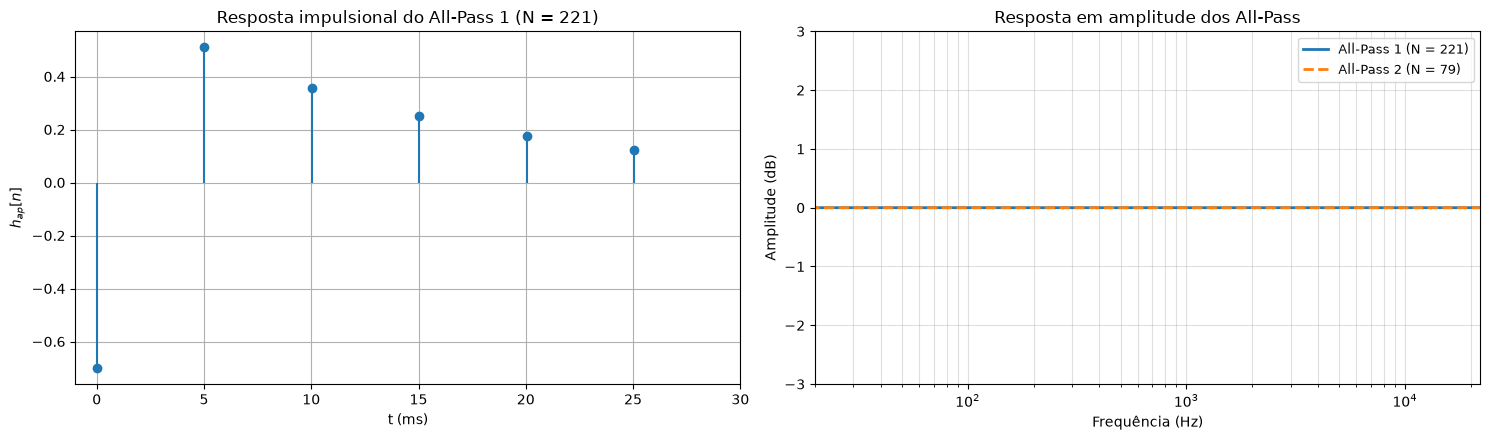

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
nz = np.flatnonzero(h_ap1)
ax1.stem(1000 * nz / Fs, h_ap1[nz], basefmt=' ')
ax1.set_xlim(-1, 1000 * len(h_ap1) / Fs)
ax1.set_xlabel('t (ms)'); ax1.set_ylabel(r'$h_{ap}[n]$')
ax1.set_title(f'Resposta impulsional do All-Pass 1 (N = {N_AP[0]})')

for k, (f, H) in enumerate(H_aps):
    ax2.plot(f, db(H), lw=2, ls=['-', '--'][k], label=f'All-Pass {k + 1} (N = {N_AP[k]})')
format_freq_axis(ax2, 'Resposta em amplitude dos All-Pass', ylim=(-3, 3), marks=())
plt.tight_layout(); plt.show()

#### Interpretação

O primeiro impulso de $h_{ap}[n]$ vale $-a = -0{,}7$. Seguem-se impulsos espaçados de 221 amostras (5,01 ms), com amplitude decrescente. A resposta em amplitude é 0 dB em todas as frequências, por isso o All-Pass multiplica o número de impulsos sem colorir o som.

### 2.4 Reverberador completo

A saída do banco de Comb é $x_{ap}[n] = \sum_{k=1}^{4} y_{c,k}[n]$. Este sinal passa pelos dois All-Pass em série. A função de transferência do reverberador é

$$H_{reverb}(z) = \left(\sum_{k=1}^{4} H_{c,k}(z)\right) H_{ap,1}(z)\, H_{ap,2}(z).$$

Todos os pólos estão no interior do círculo de raio unitário, pelo que o reverberador é estável.

Num Comb, a amplitude é multiplicada por $g$ a cada $N$ amostras, o que corresponde a um decaimento de $20\log_{10} g$ dB a cada $N/F_s$ segundos. O tempo de reverberação, ou tempo de decaimento de 60 dB, é

$$T_{60} = \frac{-3\, N}{F_s \log_{10} g}.$$

In [18]:
def reverb(x):
    """Aplica o reverberador de Schroeder (4 Comb em paralelo + 2 All-Pass em série).

    Args:
        x: Sinal de entrada.

    Returns:
        y_reverb, com o comprimento de x.
    """
    y = sum(lfilter(*comb_coefs(N, g), x) for N, g in zip(N_COMB, G_COMB))
    for N in N_AP:
        y = lfilter(*allpass_coefs(N, A_AP), y)
    return y


def t60(N, g):
    """Tempo de decaimento de 60 dB de um filtro Comb.

    Args:
        N: Atraso (amostras).
        g: Ganho de realimentação.

    Returns:
        T60 (s).
    """
    return -3 * N / (Fs * np.log10(g))


T60_COMB = [t60(N, g) for N, g in zip(N_COMB, G_COMB)]

### 2.5 Resposta impulsional

A resposta impulsional $h[n]$ do reverberador obtém-se com $x[n] = \delta[n]$. Para a analisar, o sinal é dividido em janelas de 10 ms. Em cada janela calcula-se a densidade, que é o número de amostras não nulas de $h[n]$, e a energia em dB, $10\log_{10}\sum h^2[n]$.

In [19]:
h_rev = reverb(unit_impulse(3 * Fs))

WIN = int(0.010 * Fs)
frames = h_rev[:len(h_rev) // WIN * WIN].reshape(-1, WIN)
t_frames = (np.arange(len(frames)) + 0.5) * WIN / Fs
density = np.count_nonzero(frames, axis=1)
energy_db = 10 * np.log10(np.sum(frames**2, axis=1) + 1e-20)

T60 dos filtros Comb: 0.71 s, 0.89 s, 0.99 s, 1.05 s


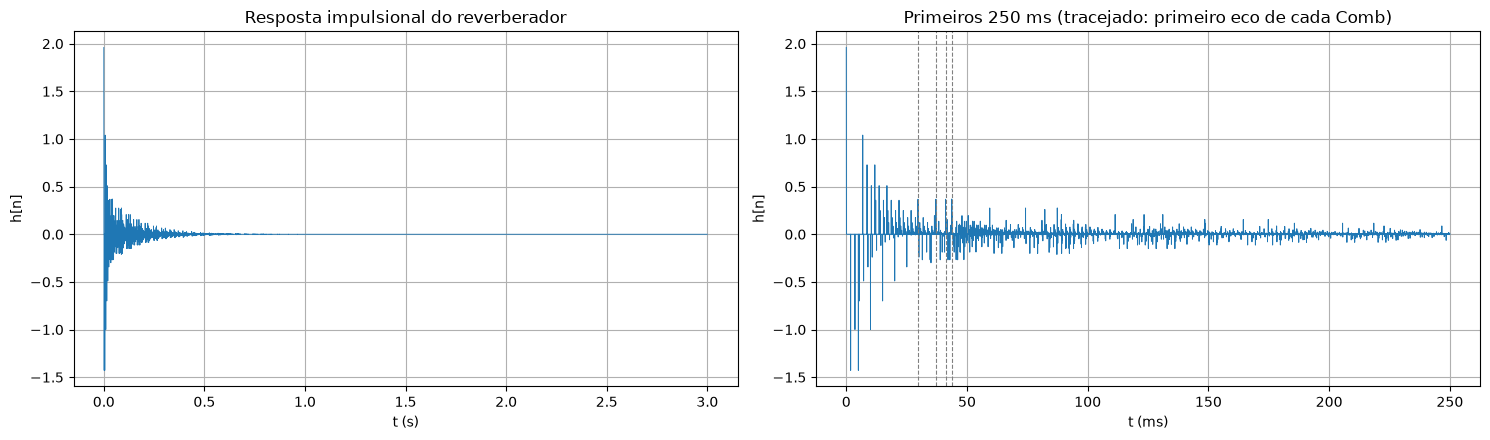

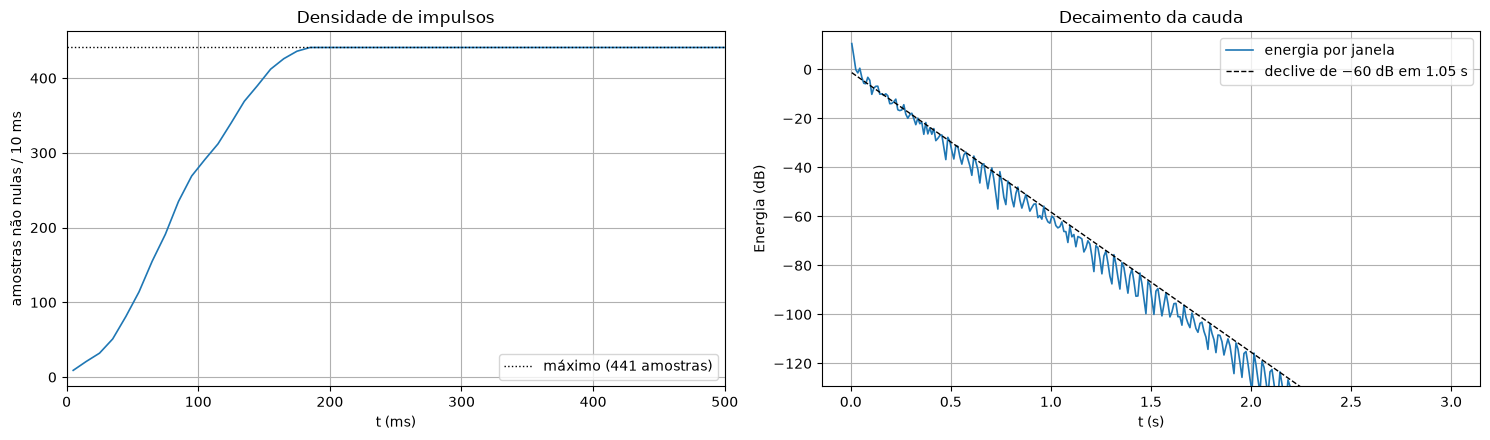

In [20]:
print('T60 dos filtros Comb:', ', '.join(f'{t:.2f} s' for t in T60_COMB))

t_h = np.arange(len(h_rev)) / Fs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
ax1.plot(t_h, h_rev, lw=0.6)
ax1.set_xlabel('t (s)'); ax1.set_ylabel('h[n]'); ax1.set_title('Resposta impulsional do reverberador')
lim = int(0.250 * Fs)
ax2.plot(1000 * t_h[:lim], h_rev[:lim], lw=0.7)
for N in N_COMB:
    ax2.axvline(1000 * N / Fs, color='gray', ls='--', lw=0.8)
ax2.set_xlabel('t (ms)'); ax2.set_ylabel('h[n]')
ax2.set_title('Primeiros 250 ms (tracejado: primeiro eco de cada Comb)')
plt.tight_layout(); plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
ax1.plot(1000 * t_frames, density, lw=1.2)
ax1.axhline(WIN, color='k', ls=':', lw=1, label=f'máximo ({WIN} amostras)')
ax1.set_xlim(0, 500); ax1.set_xlabel('t (ms)'); ax1.set_ylabel('amostras não nulas / 10 ms')
ax1.set_title('Densidade de impulsos'); ax1.legend()
ax2.plot(t_frames, energy_db, lw=1.2, label='energia por janela')
i0 = np.argmin(np.abs(t_frames - 0.5))
ax2.plot(t_frames, energy_db[i0] - 60 * (t_frames - t_frames[i0]) / max(T60_COMB), 'k--', lw=1,
         label=f'declive de −60 dB em {max(T60_COMB):.2f} s')
ax2.set_xlabel('t (s)'); ax2.set_ylabel('Energia (dB)'); ax2.set_ylim(energy_db.max() - 140, energy_db.max() + 5)
ax2.set_title('Decaimento da cauda'); ax2.legend()
plt.tight_layout(); plt.show()

#### Interpretação

Nos primeiros milissegundos, $h[n]$ tem apenas impulsos isolados. Resultam de $\delta[n]$ espalhado pelos All-Pass, com espaçamentos de 221 e 79 amostras. Os primeiros ecos dos Comb surgem entre 29,7 e 43,7 ms (linhas a tracejado), e cada um deles é também espalhado pelos All-Pass. A densidade de impulsos cresce assim com o tempo. A partir de cerca de 185 ms, todas as amostras de $h[n]$ são não nulas e os ecos deixam de se distinguir.

A energia decai de forma aproximadamente linear em dB, o que corresponde a um decaimento exponencial da cauda. O declive acompanha a referência de −60 dB em 1,05 s, que é o $T_{60}$ do Comb 4. Os Comb com menor atraso decaem mais depressa, pelo que a parte final da cauda é dominada pelo Comb 4.

## 3. Processador completo

O processador liga o equalizador e o reverberador em série e faz a mistura definida na introdução. Antes de processar, acrescentam-se zeros ao fim da entrada, com a duração do maior $T_{60}$, para que a cauda de reverberação fique completa na saída. No fim, a saída é normalizada pelo pico ($\max|y| = 0{,}99$). Esta normalização evita o *clipping* e só altera o volume.

In [21]:
def processor(x, gains, alpha):
    """Aplica o processador completo: equalizador, reverberador e mistura.

    Args:
        x: Sinal de entrada.
        gains: Ganhos do equalizador (g1, g2, g3).
        alpha: Proporção de som reverberado, em [0, 1].

    Returns:
        y normalizado, com a cauda de reverberação acrescentada.
    """
    x = np.concatenate([x, np.zeros(round(max(T60_COMB) * Fs))])
    x_eq = equalizer(x, *gains)
    return normalize((1 - alpha) * x_eq + alpha * reverb(x_eq))

## 4. Teste com áudio real

O teste usa dois sinais secos, uma voz e um instrumento. Cada sinal é processado com uma das configurações da secção 1.4. Os sinais originais estão em `audio/in/`, e os resultados são gravados em `audio/out/` com o mesmo nome.

O banco de Comb tem ganho 16 em $f = 0$ (secção 2.2), pelo que o som reverberado tem amplitude muito superior à do som direto. Por isso, o teste usa um valor baixo, $\alpha = 0{,}25$, para que o som direto continue audível.

In [22]:
TESTS = {'voz_seca':         CONFIGS[1],
         'instrumento_seco': CONFIGS[0]}

ALPHA = 0.25    # proporção de som reverberado

os.makedirs(AUDIO_OUT, exist_ok=True)
signals = {}
for name, (gains, _) in TESTS.items():
    x = read_wav(os.path.join(AUDIO_IN, f'{name}.wav'))
    y = processor(x, gains, ALPHA)
    write_wav(os.path.join(AUDIO_OUT, f'{name}.wav'), y)
    signals[name] = (x, y)

C:\Users\bruno\AppData\Local\Temp\ipykernel_32880\529931341.py:42: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(path)


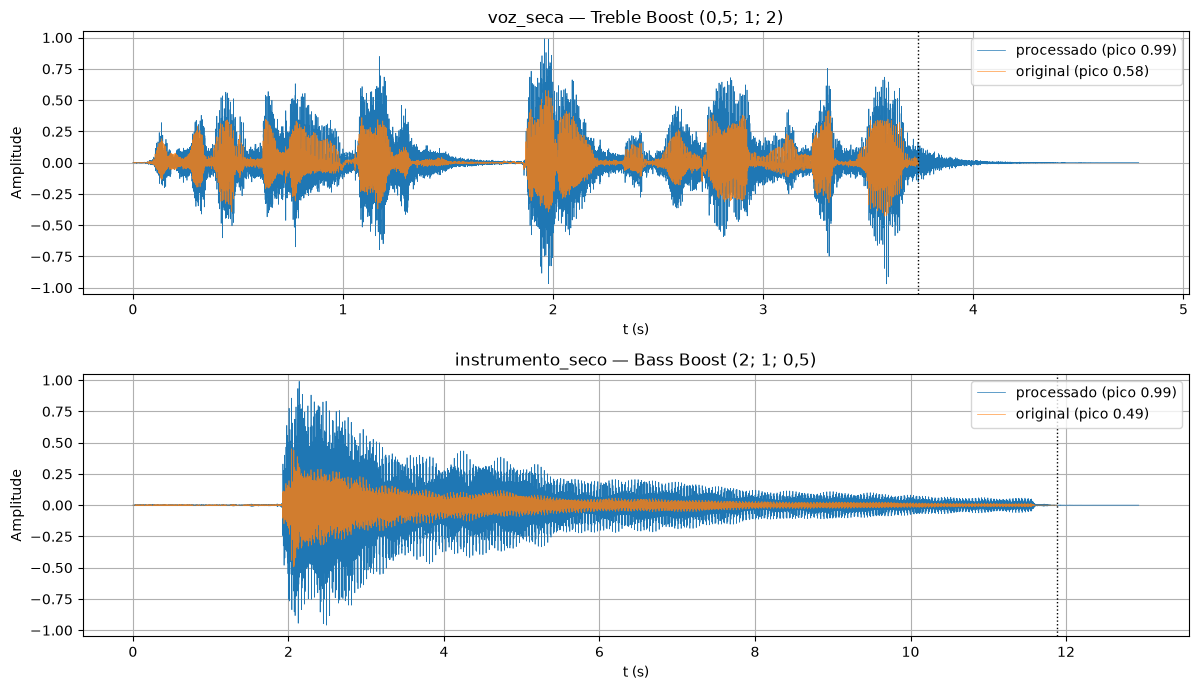

In [23]:
fig, axs = plt.subplots(len(signals), 1, figsize=(12, 3.5 * len(signals)))
for ax, (name, (x, y)) in zip(axs, signals.items()):
    ax.plot(np.arange(len(y)) / Fs, y, lw=0.5, label=f'processado (pico {np.max(np.abs(y)):.2f})')
    ax.plot(np.arange(len(x)) / Fs, x, lw=0.5, alpha=0.8, label=f'original (pico {np.max(np.abs(x)):.2f})')
    ax.axvline(len(x) / Fs, color='k', ls=':', lw=1)
    ax.set_xlabel('t (s)'); ax.set_ylabel('Amplitude'); ax.set_ylim(-1.05, 1.05)
    ax.set_title(f'{name} — {TESTS[name][1]}'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

In [24]:
for name, (x, y) in signals.items():
    print(f'{name} — original'); display(Audio(x, rate=Fs))
    print(f'{name} — processado'); display(Audio(y, rate=Fs))

voz_seca — original


voz_seca — processado


instrumento_seco — original


instrumento_seco — processado


#### Interpretação

O pico da saída é 0,99 nos dois sinais, pelo que não há *clipping*. Depois do fim do sinal original (linha a ponteado), a saída continua com a cauda de reverberação, que decai até ao silêncio no intervalo acrescentado. Nas pausas da voz, o sinal processado mantém a cauda da sílaba anterior.

## 5. Conclusões

Os três filtros FIR do equalizador têm fase linear e o mesmo atraso de 50 amostras. Associados em paralelo, equivalem a um único filtro FIR. Nos médios e nos agudos, o equalizador produz os ganhos previstos. Nos graves isso não acontece, porque com 101 coeficientes a banda de transição (cerca de 1,4 kHz) é mais larga do que a própria banda. O passa-baixo e o passa-banda sobrepõem-se, e o ganho fica em +7,4 dB e −1,4 dB em vez de ±6 dB.

No reverberador, todos os pólos estão no interior do círculo de raio unitário, pelo que o sistema é estável. Os atrasos primos entre si evitam que picos e ecos de filtros diferentes coincidam. Os filtros Comb definem o tempo de reverberação, e os All-Pass aumentam a densidade de impulsos sem colorir o som. A cauda decai de forma exponencial, ou seja, linear em dB.

No processador completo, a normalização pelo pico mantém a saída no intervalo $[-1, 1]$, e a extensão do sinal preserva a cauda de reverberação.